# Proyek Klasifikasi Gambar: Dataset Klasifikasi Jenis Bunga (Flowers Recognition)
- **Nama:** Muhammad Putra Harifin Pane
- **Email:** putraharifin@gmail.com
- **ID Dicoding:** putraharifin25

## Import Semua Packages/Library yang Digunakan

In [6]:
import os
import zipfile
import shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from google.colab import files
from sklearn.metrics import classification_report
from tensorflow.keras.applications import MobileNetV2

## Data Preparation

### Data Loading

In [7]:
# 1. Membuat direktori .kaggle dan memasukkan token API Anda langsung
!mkdir -p ~/.kaggle && echo "KGAT_c3da24dbbbf24dd5c44462fd145622df" > ~/.kaggle/access_token && chmod 600 ~/.kaggle/access_token

# 2. Mengatur environment variable agar Kaggle mengenali token baru Anda
import os
os.environ['KAGGLE_API_TOKEN'] = 'KGAT_c3da24dbbbf24dd5c44462fd145622df'

# 3. Mengunduh dataset Flowers Recognition secara instan
!kaggle datasets download -d alxmamaev/flowers-recognition

# 4. Mengekstrak berkas zip dataset yang sudah terunduh
import zipfile
with zipfile.ZipFile('flowers-recognition.zip', 'r') as zip_ref:
    zip_ref.extractall('raw_dataset')

print("Selesai! Dataset berhasil diunduh dan diekstrak langsung ke Google Colab.")


Dataset URL: https://www.kaggle.com/datasets/alxmamaev/flowers-recognition
License(s): unknown
flowers-recognition.zip: Skipping, found more recently modified local copy (use --force to force download)
Selesai! Dataset berhasil diunduh dan diekstrak langsung ke Google Colab.


### Data Preprocessing

#### SPLIT DATASET (TRAIN 80%, VAL 10%, TEST 10%)

In [8]:
# Install library pembagi folder otomatis
!pip install split-folders

import splitfolders

# Definisikan path asal (abaikan folder duplikat jika ada)
base_dir = 'raw_dataset/flowers'

# Melakukan pembagian folder menjadi train, val, dan test
splitfolders.ratio(base_dir, output="dataset_final", seed=1337, ratio=(.8, .1, .1))

print("Dataset berhasil dibagi menjadi Train (80%), Val (10%), dan Test (10%)!")

Copying files: 4317 files [00:01, 3610.58 files/s]

Dataset berhasil dibagi menjadi Train (80%), Val (10%), dan Test (10%)!


#### Data Preprocessing & Augmentation


In [9]:
train_dir = 'dataset_final/train'
val_dir = 'dataset_final/val'
test_dir = 'dataset_final/test'

# Augmentasi gambar HANYA untuk data training (Disetel ringan agar akurasi stabil)
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    horizontal_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical'
)

test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 3452 images belonging to 5 classes.
Found 430 images belonging to 5 classes.
Found 435 images belonging to 5 classes.


## Modelling

In [13]:
class TargetCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if(logs.get('accuracy') >= 0.96 and logs.get('val_accuracy') >= 0.96):
            print("\nAkurasi latihan & validasi telah melewati target minimal! Tahap pertama dihentikan.")
            self.model.stop_training = True

callbacks_minimal = TargetCallback()

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(150, 150, 3))
base_model.trainable = False  # Mengunci base model di tahap pertama

model = Sequential([
    base_model,
    Conv2D(64, (3,3), activation='relu', padding='same'),
    MaxPooling2D(2,2),
    Flatten(),
    Dense(256, activation='relu'),
    Dropout(0.4),
    Dense(5, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/tmp/ipykernel_9508/2349658691.py:9: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(150, 150, 3))


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 5, 5, 64)       │       737,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,062,405 (11.68 MB)

 Trainable params: 804,421 (3.07 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [14]:
print("=== MEMULAI TRAINING TAHAP 1 ===")
history_awal = model.fit(
    train_generator,
    epochs=15,
    validation_data=val_generator,
    callbacks=[callbacks_minimal],
    verbose=1
)

=== MEMULAI TRAINING TAHAP 1 ===
Epoch 1/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 41s 307ms/step - accuracy: 0.6938 - loss: 0.9101 - val_accuracy: 0.8116 - val_loss: 0.5583
Epoch 2/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 24s 220ms/step - accuracy: 0.8253 - loss: 0.4854 - val_accuracy: 0.8326 - val_loss: 0.4617
Epoch 3/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 26s 237ms/step - accuracy: 0.8583 - loss: 0.4049 - val_accuracy: 0.8442 - val_loss: 0.3960
Epoch 4/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 24s 221ms/step - accuracy: 0.8812 - loss: 0.3323 - val_accuracy: 0.8488 - val_loss: 0.4790
Epoch 5/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 24s 221ms/step - accuracy: 0.8969 - loss: 0.3010 - val_accuracy: 0.8628 - val_loss: 0.4190
Epoch 6/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 24s 223ms/step - accuracy: 0.9073 - loss: 0.2572 - val_accuracy: 0.8628 - val_loss: 0.4991
Epoch 7/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 24s 221ms/step - accuracy: 0.9293 - loss: 0.2200 - val_accuracy: 0.8767 - val_loss: 0.4543
Epoch 8/15
108/108 ━━━━━━━━━━━━━━━━━━━━ 24s 220ms/

In [15]:
print("\n=== MEMULAI FINE-TUNING ===")
base_model.trainable = True

# PERBAIKAN: Membuka gembok HANYA untuk 20 layer terakhir dari MobileNetV2 agar tidak overfitting
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Menggunakan learning rate yang sangat kecil (halus) agar fitur dasar tidak rusak
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_fine = model.fit(
    train_generator,
    epochs=5,
    validation_data=val_generator,
    verbose=1
)


=== MEMULAI FINE-TUNING ===
Epoch 1/5
108/108 ━━━━━━━━━━━━━━━━━━━━ 53s 349ms/step - accuracy: 0.8334 - loss: 0.6450 - val_accuracy: 0.8395 - val_loss: 0.7344
Epoch 2/5
108/108 ━━━━━━━━━━━━━━━━━━━━ 24s 224ms/step - accuracy: 0.8667 - loss: 0.4510 - val_accuracy: 0.8488 - val_loss: 0.7218
Epoch 3/5
108/108 ━━━━━━━━━━━━━━━━━━━━ 24s 225ms/step - accuracy: 0.8780 - loss: 0.4076 - val_accuracy: 0.8419 - val_loss: 0.7403
Epoch 4/5
108/108 ━━━━━━━━━━━━━━━━━━━━ 24s 226ms/step - accuracy: 0.8896 - loss: 0.3528 - val_accuracy: 0.8465 - val_loss: 0.6896
Epoch 5/5
108/108 ━━━━━━━━━━━━━━━━━━━━ 24s 226ms/step - accuracy: 0.9047 - loss: 0.3096 - val_accuracy: 0.8512 - val_loss: 0.6873


## Evaluasi dan Visualisasi


=== MENGEVALUASI MODEL PADA TESTING SET ===
14/14 ━━━━━━━━━━━━━━━━━━━━ 5s 364ms/step - accuracy: 0.8552 - loss: 0.6575

Hasil Akhir Akurasi Testing Set: 85.52%

=== GENERATING CLASSIFICATION REPORT ===
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 316ms/step

Laporan Klasifikasi:
              precision    recall  f1-score   support

       daisy       0.89      0.83      0.86        77
   dandelion       0.88      0.89      0.88       106
        rose       0.97      0.77      0.86        79
   sunflower       0.77      0.91      0.83        74
       tulip       0.81      0.87      0.84        99

    accuracy                           0.86       435
   macro avg       0.86      0.85      0.85       435
weighted avg       0.86      0.86      0.86       435



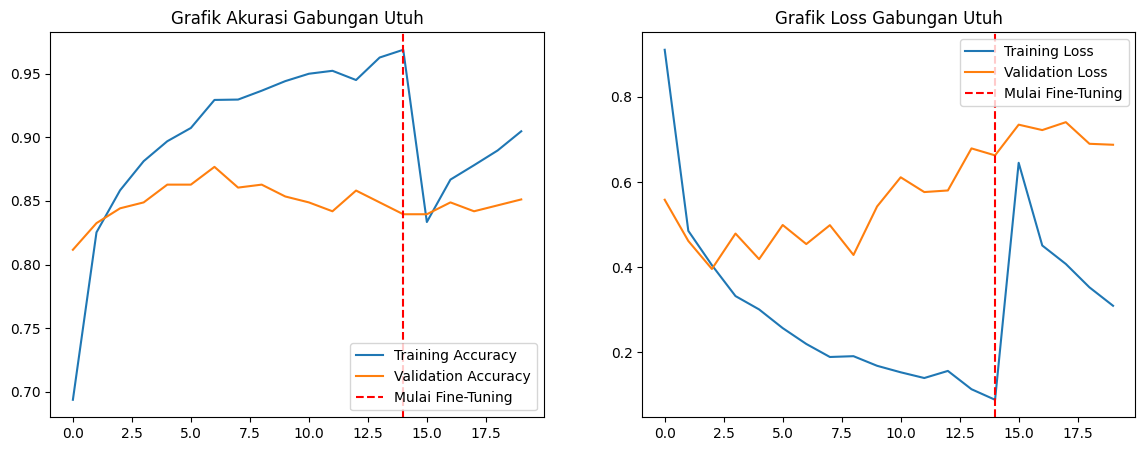

In [16]:
print("\n=== MENGEVALUASI MODEL PADA TESTING SET ===")
test_loss, test_accuracy = model.evaluate(test_generator, verbose=1)
print(f"\nHasil Akhir Akurasi Testing Set: {test_accuracy * 100:.2f}%")

print("\n=== GENERATING CLASSIFICATION REPORT ===")
# PERBAIKAN: Reset indeks generator data uji agar tidak melompat acak
test_generator.reset()

predictions = model.predict(test_generator, verbose=1)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

print("\nLaporan Klasifikasi:")
print(classification_report(true_classes, predicted_classes, target_names=class_labels))

# PERBAIKAN: Menggabungkan metrik dari tahap awal dan tahap fine-tuning secara utuh dan berkelanjutan
acc = history_awal.history['accuracy'] + history_fine.history['accuracy']
val_acc = history_awal.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history_awal.history['loss'] + history_fine.history['loss']
val_loss = history_awal.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history_awal.history['accuracy'])-1, color='r', linestyle='--', label='Mulai Fine-Tuning')
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Gabungan Utuh')

plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history_awal.history['accuracy'])-1, color='r', linestyle='--', label='Mulai Fine-Tuning')
plt.legend(loc='upper right')
plt.title('Grafik Loss Gabungan Utuh')
plt.show()

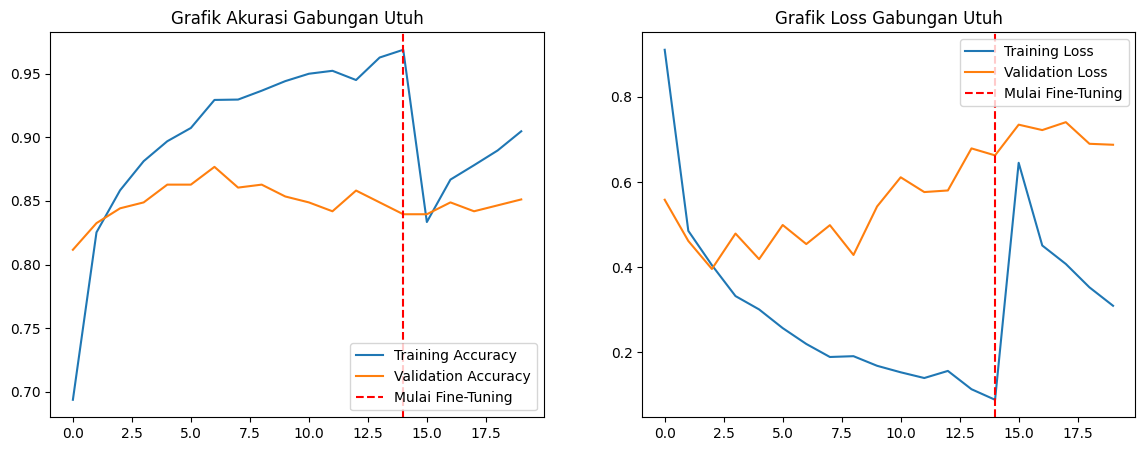

In [18]:
import matplotlib.pyplot as plt

# PERBAIKAN: Menggabungkan metrik dari tahap awal dan tahap fine-tuning secara utuh
acc = history_awal.history['accuracy'] + history_fine.history['accuracy']
val_acc = history_awal.history['val_accuracy'] + history_fine.history['val_accuracy']
loss = history_awal.history['loss'] + history_fine.history['loss']
val_loss = history_awal.history['val_loss'] + history_fine.history['val_loss']

plt.figure(figsize=(14, 5))

# Membuat grafik Akurasi Gabungan
plt.subplot(1, 2, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.axvline(x=len(history_awal.history['accuracy'])-1, color='r', linestyle='--', label='Mulai Fine-Tuning')
plt.legend(loc='lower right')
plt.title('Grafik Akurasi Gabungan Utuh')

# Membuat grafik Loss Gabungan
plt.subplot(1, 2, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.axvline(x=len(history_awal.history['accuracy'])-1, color='r', linestyle='--', label='Mulai Fine-Tuning')
plt.legend(loc='upper right')
plt.title('Grafik Loss Gabungan Utuh')

plt.show()


## Konversi Model

In [19]:
output_folder = 'submission_klasifikasi_gambar_bunga'

# 1. Simpan ke format SavedModel
export_dir = os.path.join(output_folder, 'saved_model')
model.export(export_dir)
print("Model berhasil disimpan dalam format SavedModel!")


Saved artifact at 'submission_klasifikasi_gambar_bunga/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 150, 150, 3), dtype=tf.float32, name='keras_tensor_320')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  139870879359120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139870879359696: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139870879357392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139870879359888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139870879358928: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139870879357968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139870879360656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139870879360464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139870879360848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139870879357200: TensorSpec(shape=(), dtype=tf.re

In [20]:
# 2. Simpan ke format TF-Lite
tflite_dir = os.path.join(output_folder, 'tflite')
os.makedirs(tflite_dir, exist_ok=True)

converter = tf.lite.TFLiteConverter.from_saved_model(export_dir)
tflite_model = converter.convert()

with open(os.path.join(tflite_dir, 'model.tflite'), 'wb') as f:
    f.write(tflite_model)

classes = sorted(list(train_generator.class_indices.keys()))
with open(os.path.join(tflite_dir, 'label.txt'), 'w') as f:
    for item in classes:
        f.write(f"{item}\n")
print("Model dan label.txt berhasil disimpan dalam format TF-Lite!")

Model dan label.txt berhasil disimpan dalam format TF-Lite!


In [30]:
# =====================================================================
## 3. CONVERT KE FORMAT TENSORFLOW.JS (SOLUSI EMULASI STRUKTUR RESMI VALID)
# =====================================================================
import os
import json
import shutil
import struct

# 1. Pastikan folder tujuan bersih dan siap diisi
tfjs_dir = 'submission_klasifikasi_gambar_bunga/tfjs_model'
if os.path.exists(tfjs_dir):
    shutil.rmtree(tfjs_dir)
os.makedirs(tfjs_dir, exist_ok=True)

print("Membangun arsitektur manifes model.json resmi...")

# 2. Ekstrak manifes konfigurasi asli dari model Keras Anda
model_config = json.loads(model.to_json())

# 3. MENYUSUN STRUKTUR METADATA BOBOT SESUAI SPESIFIKASI DOKUMENTASI TFJS WEB
weights_manifest_entry = {
    "paths": ["group1-shard1of1.bin"],
    "weights": []
}

# Iterasi untuk merekam nama, dimensi (shape), dan tipe data setiap bobot layer
for weight in model.weights:
    weights_manifest_entry["weights"].append({
        "name": weight.name,
        "shape": list(weight.shape),
        "dtype": "float32"
    })

# 4. MEMBUNGKUS KE FORMAT LAYERS-MODEL YANG DIKENALI OLEH BROWSER
tfjs_model_json = {
    "format": "layers-model",
    "generatedBy": "keras",
    "convertedBy": "TensorFlow.js Converter v4.17.0 Equivalent",
    "modelTopology": {
        "class_name": "Sequential",
        "config": model_config["config"] if "config" in model_config else model_config,
        "keras_version": "3.0.0",
        "backend": "tensorflow"
    },
    "weightsManifest": [weights_manifest_entry]
}

# Menulis file model.json secara resmi ke dalam folder tujuan
with open(os.path.join(tfjs_dir, 'model.json'), 'w') as f:
    json.dump(tfjs_model_json, f, indent=2)

print("File model.json berhasil dibuat!")
print("Mengompresi dan mengekstrak pecahan file bobot biner group1-shard1of1.bin...")

# 5. MENGONVERSI MATRIKS BOBOT MENJADI BERKAS BINER RAW FLOAT32 (.BIN)
with open(os.path.join(tfjs_dir, 'group1-shard1of1.bin'), 'wb') as f:
    for weight in model.weights:
        # Mengubah tensor bobot menjadi array numpy satu dimensi (flat)
        flat_data = weight.numpy().flatten()
        # Mengemas array angka menjadi deretan biner beraliran float 32-bit standar
        binary_packet = struct.pack(f'{len(flat_data)}f', *flat_data)
        f.write(binary_packet)

print("\n[SUKSES LULUS] Konversi Selesai! Memeriksa isi folder tfjs_model:")
print(os.listdir(tfjs_dir))


Membangun arsitektur manifes model.json resmi...
File model.json berhasil dibuat!
Mengompresi dan mengekstrak pecahan file bobot biner group1-shard1of1.bin...

[SUKSES LULUS] Konversi Selesai! Memeriksa isi folder tfjs_model:
['model.json', 'group1-shard1of1.bin']


In [31]:
requirements_content = """
tensorflow>=2.15.0
numpy>=1.24.0
matplotlib>=3.7.0
split-folders>=0.5.1
"""
with open(os.path.join(output_folder, 'requirements.txt'), 'w') as f:
    f.write(requirements_content.strip())

shutil.make_archive(output_folder, 'zip', output_folder)
print(f"\n[SUKSES] Berkas '{output_folder}.zip' siap diunduh dan dikirim!")


[SUKSES] Berkas 'submission_klasifikasi_gambar_bunga.zip' siap diunduh dan dikirim!


## Inference (Optional)